<div align="center">

# Classify text with a trained linear head

Train a text classifier, compare its accuracy, and save it for your app.

</div>

## When do you need this?

You want to sort reviews by sentiment or route news by topic.
You need a saved model that predicts labels directly from text in your app.
**Train outside fse**, then import the finished linear head.

## The story in pictures

![The same training texts feed four classifiers. Unseen test texts compare accuracy. Save the fse classifier for your app.](media/02-linear-heads.svg)

A **linear head** is a small trained model that turns vectors into labels or scores.
We compare fse with Model2Vec's own classifier, TF-IDF plus logistic regression, and fastText.
TF-IDF counts words and gives common words less weight, while logistic regression learns how those features predict labels.
fastText learns its own word vectors and classifier from the training texts.

## 1. Load two real datasets

[SST-5](https://huggingface.co/datasets/SetFit/sst5) contains movie reviews with five sentiment labels.
[AG News](https://huggingface.co/datasets/SetFit/ag_news) has four news topics.
We keep their published test splits separate and use a fixed, stratified sample for AG News, keeping each class represented.
The [helper](_helpers.py) pins both dataset revisions, and the [index](README.md#run-a-recipe) covers installation.

In [1]:
from _helpers import Recipe
import fse
import numpy as np

recipe = Recipe()
work = recipe.work

Recipe run: 2026-11-01. Generated files are temporary.
Apple M1 Pro. macOS-27.0.1-arm64-arm-64bit-Mach-O. Python 3.13.16.


In [2]:
import fse
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 7
datasets = {}
for name in ("SST-5", "AG News"):
    train_texts, train_labels = recipe.dataset(name, "train")
    test_texts, test_labels = recipe.dataset(name, "test")
    if name == "AG News":
        train_texts, _, train_labels, _ = train_test_split(
            train_texts,
            train_labels,
            train_size=8000,
            stratify=train_labels,
            random_state=SEED,
        )
        test_texts, _, test_labels, _ = train_test_split(
            test_texts,
            test_labels,
            train_size=2000,
            stratify=test_labels,
            random_state=SEED,
        )
    fit_x, val_x, fit_y, val_y = train_test_split(
        train_texts,
        train_labels,
        test_size=0.2,
        stratify=train_labels,
        random_state=SEED,
    )
    datasets[name] = (fit_x, fit_y, val_x, val_y, test_texts, test_labels)
    print(name, {"fit": len(fit_x), "validation": len(val_x), "test": len(test_texts)})

/Users/oliverborchers/.herdr/worktrees/Fast_Sentence_Embeddings/dr195-tutorials/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SST-5 {'fit': 6835, 'validation': 1709, 'test': 2210}


AG News {'fit': 6400, 'validation': 1600, 'test': 2000}


## 2. Train the fse head

POTION-base-8M supplies the vectors for a scikit-learn logistic regression head.
**Every method sees the same fit and test texts**, with validation texts reserved for Model2Vec's early stopping.
We use fixed settings rather than tune on test results.
POTION vectors have unit length here, so fse keeps that normalization when running the head.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

encoder = recipe.encoder()
results = []
classifiers = {}


def record(dataset, method, expected, predicted):
    results.append(
        {
            "dataset": dataset,
            "method": method,
            "accuracy": float(accuracy_score(expected, predicted)),
            "macro_f1": float(f1_score(expected, predicted, average="macro")),
        }
    )


for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    train_rows = encoder.encode(fit_x, workers=1)
    test_rows = encoder.encode(test_x, workers=1)
    head = LogisticRegression(C=1, max_iter=1000, random_state=SEED).fit(train_rows, fit_y)
    classifier = fse.Classifier.from_sklearn(encoder, head)
    predicted = classifier.predict(test_x, workers=1)
    np.testing.assert_array_equal(predicted, head.predict(test_rows))
    np.testing.assert_allclose(
        classifier.predict_proba(test_x, workers=1),
        head.predict_proba(test_rows),
        atol=3e-6,
    )
    classifiers[name] = classifier
    record(name, "fse + linear head", test_y, predicted)

## 3. Train the word-count baseline

A **baseline** is a simple method used as a comparison.
TF-IDF learns its vocabulary on fit texts only, including adjacent word pairs.
It never sees test texts while fitting.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline

for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    baseline = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000),
        LogisticRegression(C=1, max_iter=1000, random_state=SEED),
    )
    baseline.fit(fit_x, fit_y)
    record(name, "TF-IDF + logistic regression", test_y, baseline.predict(test_x))

## 4. Train Model2Vec's own classifier

[Model2Vec 0.10.0](https://github.com/MinishLab/model2vec/blob/v0.10.0/model2vec/train/classifier.py) starts from the same POTION snapshot.
Unlike the fixed fse encoder, **this method updates word vectors** and trains a head with one hidden layer of 512 units.
It gets at most 10 epochs, passes through the training data, with early stopping after three checks without a validation gain.
This compares complete training methods, rather than treating their differences as an engine accuracy gap.

In [5]:
import torch
from model2vec import StaticModel
from model2vec.train import StaticModelForClassification

torch.set_num_threads(1)
for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    base = StaticModel.from_pretrained(recipe.model_folder())
    model = StaticModelForClassification.from_static_model(
        model=base,
        n_layers=1,
        hidden_dim=512,
        freeze=False,
        normalize=True,
    )
    model.fit(
        fit_x,
        fit_y.tolist(),
        X_val=val_x,
        y_val=val_y.tolist(),
        device="cpu",
        batch_size=128,
        learning_rate=1e-3,
        max_epochs=10,
        early_stopping_patience=3,
        random_seed=SEED,
    )
    record(name, "Model2Vec classifier (fine-tuned)", test_y, model.predict(test_x))

Epoch 1:   0%|          | 0/54 [00:00<?, ?step/s]

Epoch 1:   0%|          | 0/54 [00:00<?, ?step/s, train_loss=1.6153, train_accuracy=0.1953]

Epoch 1:   2%|▏         | 1/54 [00:00<00:05,  9.26step/s, train_loss=1.6153, train_accuracy=0.1953]

Epoch 1:   2%|▏         | 1/54 [00:00<00:05,  9.26step/s, train_loss=1.6101, train_accuracy=0.1953]

Epoch 1:   2%|▏         | 1/54 [00:00<00:05,  9.26step/s, train_loss=1.6100, train_accuracy=0.2031]

...

Epoch 7:  84%|████████▍ | 42/50 [00:00<00:00, 50.67step/s, train_loss=0.2174, train_accuracy=0.9292, val_loss=0.3106, val_accuracy=0.8969]

Epoch 7:  96%|█████████▌| 48/50 [00:00<00:00, 51.38step/s, train_loss=0.2174, train_accuracy=0.9292, val_loss=0.3106, val_accuracy=0.8969]

Epoch 7:  96%|█████████▌| 48/50 [00:00<00:00, 51.38step/s, train_loss=0.2188, train_accuracy=0.9294, val_loss=0.3106, val_accuracy=0.8969]

Epoch 7:  96%|█████████▌| 48/50 [00:00<00:00, 51.38step/s, train_loss=0.2205, train_accuracy=0.9286, val_loss=0.3106, val_accuracy=0.8969]

Epoch 7: 100%|██████████| 50/50 [00:00<00:00, 51.21step/s, train_loss=0.2205, train_accuracy=0.9286, val_loss=0.3106, val_accuracy=0.8969]

## 5. Train fastText

The pinned fastText 0.9.3 builds on Python 3.13 for this run.
Its **supervised classifier** learns from the same fit texts, without pretrained POTION vectors.
We use word pairs, 100 dimensions, 25 epochs, and one thread with a fixed seed.

In [6]:
import fasttext

for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    training_file = work / (name.replace(" ", "-") + ".txt")
    training_file.write_text(
        "\n".join(
            f"__label__{label} " + " ".join(text.split())
            for text, label in zip(fit_x, fit_y, strict=True)
        )
        + "\n",
        encoding="utf-8",
    )
    fast = fasttext.train_supervised(
        input=str(training_file),
        dim=100,
        wordNgrams=2,
        epoch=25,
        lr=0.5,
        bucket=100000,
        minCount=1,
        loss="softmax",
        thread=1,
        seed=SEED,
        verbose=0,
    )
    labels, _ = fast.predict([" ".join(t.split()) for t in test_x], k=1)
    predicted = [int(row[0].removeprefix("__label__")) for row in labels]
    record(name, "fastText", test_y, predicted)

## Result: compare quality on unseen texts

**Macro-F1 gives every class equal weight**, even when some sentiment classes have fewer examples.
Accuracy is the fraction of correct labels, and both scores range from zero to one.
Use macro-F1 as the main SST-5 comparison and accuracy for the balanced AG News sample.
These are single fixed-seed runs with limited training settings, rather than a general ranking.

Matplotlib is building the font cache; this may take a moment.


| Dataset | Method | Accuracy | Macro-F1 |
|---|---|---:|---:|
| SST-5 | fse + linear head | 0.4005 | 0.3708 |
| AG News | fse + linear head | 0.8780 | 0.8777 |
| SST-5 | TF-IDF + logistic regression | 0.3900 | 0.3209 |
| AG News | TF-IDF + logistic regression | 0.8750 | 0.8746 |
| SST-5 | Model2Vec classifier (fine-tuned) | 0.4213 | 0.3770 |
| AG News | Model2Vec classifier (fine-tuned) | 0.8805 | 0.8803 |
| SST-5 | fastText | 0.3891 | 0.3721 |
| AG News | fastText | 0.8550 | 0.8545 |

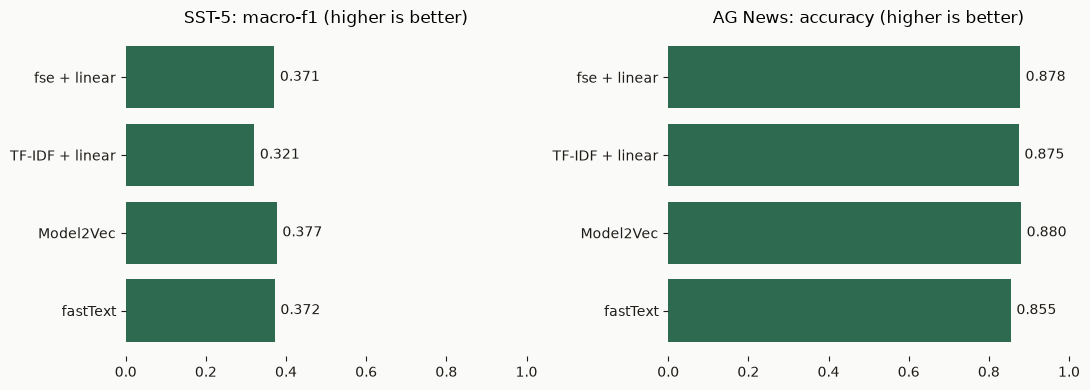

1110

In [7]:
import json
from IPython.display import Markdown, display
from _charts import quality_chart

display(
    Markdown(
        "| Dataset | Method | Accuracy | Macro-F1 |\n|---|---|---:|---:|\n"
        + "\n".join(
            f"| {r['dataset']} | {r['method']} | {r['accuracy']:.4f} | {r['macro_f1']:.4f} |"
            for r in results
        )
    )
)
quality_chart(results)
(work / "accuracy.json").write_text(json.dumps(results, indent=2))

## 6. Save a finished classifier

The saved classifier includes its encoder, so your app can **load it without scikit-learn**.
Because this head uses unit-length vectors, save the complete model with the default settings.
`standalone=True` folds a head into word rows and only works for heads trained on raw means.
The assertion checks that saving and loading preserve the test predictions.

In [8]:
classifier = classifiers["AG News"]
path = work / "news-classifier.safetensors"
classifier.save(path)
loaded = fse.Classifier.load(path)
test_x = datasets["AG News"][4]
np.testing.assert_array_equal(
    loaded.predict(test_x, workers=1), classifier.predict(test_x, workers=1)
)
topic_names = ["World", "Sports", "Business", "Science and technology"]
expected = datasets["AG News"][5]
for text, predicted, actual in zip(test_x[:5], loaded.predict(test_x[:5], workers=1), expected[:5], strict=True):
    print(f"Predicted: {topic_names[int(predicted)]}. Expected: {topic_names[int(actual)]}.")
    print(text[:160] + "\n")


Predicted: Business. Expected: Business.
Heineken Profit Dips But Repeats Outlook  AMSTERDAM (Reuters) - Dutch brewer Heineken posted a 4.5  percent fall in core profit for the first half on Wednesday,

Predicted: World. Expected: World.
The radical Islamic cleric was deported from Germany late Tuesday &lt;b&gt;...&lt;/b&gt; Turkish officials were doing what was necessary in regard to the return

Predicted: Science and technology. Expected: Sports.
Hamm should support Yang Paul Hamm needs a new marketing strategy. Either that, or he needs a clue. One harmless gesture separates him from lionization in Ameri

Predicted: Sports. Expected: Sports.
Despite struggles at plate, Boone wins Gold Glove The way Bret Boone sees it, winning a Gold Glove after a tough offensive season is a validation of the award i

Predicted: Science and technology. Expected: Science and technology.
Microsoft Fixes Key SP2 Issue (NewsFactor) NewsFactor - Microsoft (Nasdaq: MSFT) has released a Windows XP Service Pa

## Optional: predict a score instead of a label

A regression head predicts numbers.
For this example, we treat SST-5 labels 0 through 4 as equally spaced sentiment scores, which is an **explicit modeling assumption**.
Mean absolute error, or MAE, measures the average error in those label units.

In [9]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

fit_x, fit_y, _, _, test_x, test_y = datasets["SST-5"]
regression = Ridge(alpha=1).fit(encoder.encode(fit_x, workers=1), fit_y.astype(float))
regressor = fse.Regressor.from_sklearn(encoder, regression)
predicted = regressor.predict(test_x, workers=1)
np.testing.assert_allclose(
    predicted, regression.predict(encoder.encode(test_x, workers=1)), atol=3e-5
)
regressor.save(work / "sentiment-score.safetensors")
print("MAE:", round(mean_absolute_error(test_y, predicted), 4))
print(
    "Training-mean baseline MAE:",
    round(mean_absolute_error(test_y, np.full(len(test_y), fit_y.mean())), 4),
)

MAE: 0.8501
Training-mean baseline MAE: 1.141


## What next?

- [Process a file in batches](03-files-with-resume.ipynb).
- [fse API and design](../docs/architecture/formats.md)
- [scikit-learn linear models](https://scikit-learn.org/stable/modules/linear_model.html), [fastText classification](https://fasttext.cc/docs/en/supervised-tutorial.html)

Back to the [recipe index](README.md) or the [main README](../README.md).

## Clean up

The helper keeps generated files in a temporary folder. Run this after you finish exploring the results.

In [10]:
recipe.close()